<a href="https://colab.research.google.com/github/Al-harithM/CIFAR-10_CNN/blob/main/CIFAR-10_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torchvision
from torchvision.transforms import transforms
from torch.utils.data import Dataset

In [2]:
# Convert to tensors and normalize
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])

In [3]:
transforms_augmented = transforms.Compose([
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.RandomCrop(32, padding=4),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Download cifar-10 training dataset
dataset = torchvision.datasets.CIFAR10(
    root='/content/drive/MyDrive/cifar_data',
    train=True,
    download=True,
    transform=transform
)


In [6]:
augmented_dataset = torchvision.datasets.CIFAR10(
    root='/content/drive/MyDrive/cifar_data',
    train=True,
    download=True,
    transform=transforms_augmented
)


In [46]:
len(dataset)

50000

In [7]:
target_classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [8]:
trainset, testset = torch.utils.data.random_split(dataset,[0.7,0.3])

In [9]:
augmented_dataset_evens = list(range(0,len(augmented_dataset),2))
augmented_subset = torch.utils.data.Subset(augmented_dataset, augmented_dataset_evens)

complete_trainset = torch.utils.data.ConcatDataset(
    [trainset, augmented_subset]
)

In [10]:
print(f"Original Cifar-10 dataset size = {len(dataset)}")
print(f"augmented dataset size = {len(augmented_dataset)}")
print(f"augmented subset size = {len(augmented_subset)}")

Original Cifar-10 dataset size = 50000
augmented dataset size = 50000
augmented subset size = 25000


In [11]:
batch_size = 64

trainloader = torch.utils.data.DataLoader(complete_trainset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
testloader  = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print(f"Training dataset size = {len(complete_trainset)}")
print(f"Testing set size = {len(testset)}")


Training dataset size = 60000
Testing set size = 15000


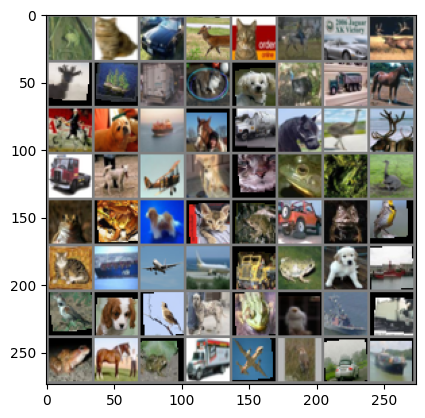

frog  cat   car   deer  cat   horse car   deer  deer  ship  truck cat   dog   bird  truck horse horse dog   ship  horse truck horse bird  deer  truck dog   plane dog   cat   frog  frog  bird  frog  frog  dog   cat   frog  car   frog  bird  cat   ship  plane plane truck frog  dog   ship  bird  dog   bird  dog   frog  bird  ship  truck frog  horse frog  truck plane bird  car   ship 


In [12]:
#show some images
import matplotlib.pyplot as plt
import numpy as np

def imshow(img):
  img = img/2 + 0.5 #unnormalize
  npimg = img.numpy()
  plt.imshow(np.transpose(npimg,(1,2,0)))
  plt.show()

#get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

#show images
imshow(torchvision.utils.make_grid(images))
print(' '.join(f'{target_classes[labels[j]]:5s}' for j in range(batch_size)))


# Define the Convolutional Neural Network

In [13]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
  def __init__(self):
    super().__init__()

    self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
    self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
    self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

    self.batchNorm1 = nn.BatchNorm2d(32)
    self.batchNorm2 = nn.BatchNorm2d(64)
    self.batchNorm3 = nn.BatchNorm2d(128)

    self.pool = nn.MaxPool2d(2, 2)

    # CIFAR-10 starts as 32x32. After 3 pooling operations:
    # 32x32 -> 16x16 -> 8x8 -> 4x4
    self.fc1 = nn.Linear(128 * 4 * 4, 120)
    self.fc2 = nn.Linear(120, 84)
    self.fc3 = nn.Linear(84, 10)

  def forward(self, x):
    x = self.pool(F.relu(self.batchNorm1(self.conv1(x))))
    x = self.pool(F.relu(self.batchNorm2(self.conv2(x))))
    x = self.pool(F.relu(self.batchNorm3(self.conv3(x))))

    x = torch.flatten(x, 1)
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = self.fc3(x)
    return x

net = Net()

# Define the Loss Function and Optimizer

In [ ]:
import torch.optim as optim
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr = 0.001, momentum = 0.9)

# Train the Network (CPU)

In [ ]:
for epoch in range(10): #Loop over the dataset multiple times
  running_loss = 0.0
  for i, data in enumerate(trainloader, 0):
    #get the inputs; data is a list of [imputs, labels]
    inputs, labels = data
    #zero the parameters gradients
    optimizer.zero_grad()
    #forward + backward + optimize
    outputs = net(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    #print Statistics
    running_loss += loss.item()
    if i % 50 == 49: #print every 50 mini batches
      print(f'[{epoch + 1}, {i +1:5d}] loss: {running_loss / 50:.3f}')
      running_loss = 0.0

print("Finished Training")

[1,    50] loss: 0.702
[1,   100] loss: 0.698
[1,   150] loss: 0.696
[1,   200] loss: 0.699
[1,   250] loss: 0.697
[2,    50] loss: 0.697
[2,   100] loss: 0.698
[2,   150] loss: 0.697
[2,   200] loss: 0.697
[2,   250] loss: 0.702
[3,    50] loss: 0.698
[3,   100] loss: 0.699
[3,   150] loss: 0.697
[3,   200] loss: 0.697
[3,   250] loss: 0.701
[4,    50] loss: 0.697
[4,   100] loss: 0.700
[4,   150] loss: 0.698
[4,   200] loss: 0.700
[4,   250] loss: 0.697
[5,    50] loss: 0.695
[5,   100] loss: 0.700
[5,   150] loss: 0.698
[5,   200] loss: 0.699
[5,   250] loss: 0.699
[6,    50] loss: 0.701
[6,   100] loss: 0.699
[6,   150] loss: 0.700
[6,   200] loss: 0.696
[6,   250] loss: 0.696
[7,    50] loss: 0.698
[7,   100] loss: 0.697
[7,   150] loss: 0.699
[7,   200] loss: 0.701
[7,   250] loss: 0.697
[8,    50] loss: 0.697
[8,   100] loss: 0.698
[8,   150] loss: 0.700
[8,   200] loss: 0.697
[8,   250] loss: 0.701
[9,    50] loss: 0.698
[9,   100] loss: 0.699
[9,   150] loss: 0.700
[9,   200] 

In [ ]:
PATH = './cifar_net.pt'
torch.save(net.state_dict(), PATH)

# Train the network on GPU

In [14]:
device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cuda


In [15]:
net = Net()
net.to(device)

Net(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchNorm1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchNorm2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchNorm3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [27]:
import torch.optim as optim

# Ensure the model is on the target device (GPU)

# Re-initialize the optimizer with the GPU model parameters
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)
criterion = nn.CrossEntropyLoss()

# Train for 20 epochs to ensure convergence
for epoch in range(20):
  running_loss = 0.0
  for i, data in enumerate(trainloader, 0):
    inputs, labels = data
    # Move inputs and labels to GPU
    inputs, labels = inputs.to(device), labels.to(device)

    optimizer.zero_grad()

    outputs = net(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    if i % 50 == 49:
      print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 50:.3f}')
      running_loss = 0.0

  print(f"Finished Training for epoch = {epoch + 1}")

[1,    50] loss: 0.528
[1,   100] loss: 0.542
[1,   150] loss: 0.505
[1,   200] loss: 0.512
[1,   250] loss: 0.466
[1,   300] loss: 0.474
[1,   350] loss: 0.515
[1,   400] loss: 0.499
[1,   450] loss: 0.513
[1,   500] loss: 0.474
[1,   550] loss: 0.456
[1,   600] loss: 0.497
[1,   650] loss: 0.473
[1,   700] loss: 0.462
[1,   750] loss: 0.477
[1,   800] loss: 0.472
[1,   850] loss: 0.479
[1,   900] loss: 0.523
Finished Training for epoch = 1
[2,    50] loss: 0.438
[2,   100] loss: 0.459
[2,   150] loss: 0.441
[2,   200] loss: 0.485
[2,   250] loss: 0.483
[2,   300] loss: 0.476
[2,   350] loss: 0.450
[2,   400] loss: 0.485
[2,   450] loss: 0.442
[2,   500] loss: 0.454
[2,   550] loss: 0.462
[2,   600] loss: 0.470
[2,   650] loss: 0.476
[2,   700] loss: 0.451
[2,   750] loss: 0.453
[2,   800] loss: 0.424
[2,   850] loss: 0.458
[2,   900] loss: 0.450
Finished Training for epoch = 2
[3,    50] loss: 0.451
[3,   100] loss: 0.405
[3,   150] loss: 0.402
[3,   200] loss: 0.432
[3,   250] loss:

In [28]:
PATH = './cifar_net.pt'
torch.save(net.state_dict(), PATH)

# Test the Network

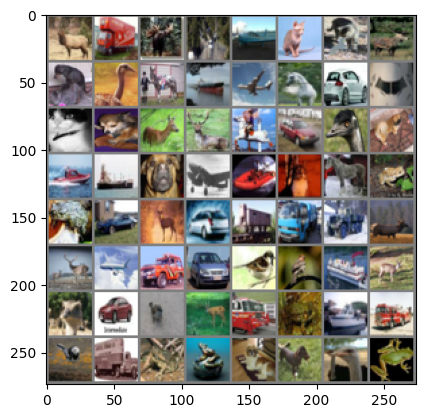

GroundTruth:  deer  truck deer  deer  plane cat   cat   deer  dog   bird  horse ship  plane horse car   plane cat   dog   deer  deer  horse car   bird  dog   ship  ship  dog   plane ship  cat   horse frog  frog  car   deer  car   truck truck truck deer  deer  plane car   car   bird  bird  ship  deer  bird  car   bird  deer  truck frog  ship  truck bird  truck frog  frog  dog   dog   bird  frog 


In [18]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{target_classes[labels[j]]:5s}' for j in range(batch_size)))

In [29]:
images = images.to(device)
outputs = net(images)

In [20]:
_, predicted = torch.max(outputs, 1)
print('Predicted: ', ' '.join(f'{target_classes[predicted[j]]:5s}' for j in range(4)))

Predicted:  deer  truck deer  dog  


In [30]:
net = Net()
net.load_state_dict(torch.load(PATH, weights_only=True))

# 1. ALWAYS set the model to evaluation mode after loading weights
net.eval()

# 2. Ensure it is moved to the target device (GPU)
net.to(device)

Net(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchNorm1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchNorm2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchNorm3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [31]:
correct = 0
total = 0

# Ensure the model is moved to the GPU for evaluation

with torch.no_grad():
  for data in testloader:
    images, labels = data
    # Move test images and labels to the GPU
    images, labels = images.to(device), labels.to(device)

    outputs = net(images)
    _, predicted = torch.max(outputs, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the {len(testset)} test images: {100 * correct / total:.2f} %')

Accuracy of the network on the 15000 test images: 80.84 %


## see the accuracy of each class:

In [32]:
correct_pred = {classname: 0 for classname in target_classes}
total_pred = {classname: 0 for classname in target_classes}

with torch.no_grad():
  for data in testloader:
    images, labels = data
    # Move images and labels to the same device as the model (GPU)
    images, labels = images.to(device), labels.to(device)

    outputs = net(images)
    _, predictions = torch.max(outputs, 1)

    for label, prediction in zip(labels, predictions):
      if label == prediction:
        correct_pred[target_classes[label]] += 1
      total_pred[target_classes[label]] += 1

  for classname, correct_count in correct_pred.items():
    if total_pred[classname] > 0:
      accuracy = 100 * float(correct_count) / total_pred[classname]
      print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')
    else:
      print(f'Accuracy for class: {classname:5s} is N/A (no samples in test set)')


Accuracy for class: plane is 88.5 %
Accuracy for class: car   is 92.3 %
Accuracy for class: bird  is 75.1 %
Accuracy for class: cat   is 63.7 %
Accuracy for class: deer  is 81.6 %
Accuracy for class: dog   is 74.3 %
Accuracy for class: frog  is 88.3 %
Accuracy for class: horse is 78.8 %
Accuracy for class: ship  is 82.2 %
Accuracy for class: truck is 83.7 %


see the number of parameters in the model

In [33]:
total_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {total_params:,}")

Total Trainable Parameters: 350,590


# ResNet18 as a BenchMark

In [37]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models


def build_resnet18(num_classes: int = 10, pretrained: bool = False, cifar_stem: bool = True) -> nn.Module:
    """
    cifar_stem=True adapts the initial conv/maxpool for 32x32 images so spatial
    resolution isn't aggressively downsampled on layer 1.
    """
    weights = models.ResNet18_Weights.DEFAULT if pretrained else None
    model = models.resnet18(weights=weights)

    if cifar_stem:
        model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        model.maxpool = nn.Identity()

    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


@torch.no_grad()
def evaluate_resnet18(model: nn.Module, loader: DataLoader, criterion: nn.Module, device: torch.device) -> tuple[float, float]:
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = 100.0 * correct / total
    return avg_loss, accuracy


def train_resnet18(
    model: nn.Module,
    train_loader: DataLoader,
    test_loader: DataLoader,
    epochs: int = 20,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu"),
) -> dict:
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            train_correct += (outputs.argmax(dim=1) == labels).sum().item()
            train_total += labels.size(0)

        scheduler.step()

        train_loss = running_loss / train_total
        train_acc = 100.0 * train_correct / train_total
        test_loss, test_acc = evaluate_resnet18(model, test_loader, criterion, device)

        if test_acc > best_acc:
            best_acc = test_acc
            best_weights = copy.deepcopy(model.state_dict())

        history.append((epoch, train_loss, train_acc, test_loss, test_acc))
        print(
            f"Epoch [{epoch:02d}/{epochs:02d}] | "
            f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
            f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}%"
        )

    model.load_state_dict(best_weights)
    final_test_loss, final_test_acc = evaluate_resnet18(model, test_loader, criterion, device)

    return {
        "best_test_acc": best_acc,
        "final_test_acc": final_test_acc,
        "final_test_loss": final_test_loss,
        "history": history,
    }


def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Running ResNet-18 on: {device}")

    train_loader = torch.utils.data.DataLoader(complete_trainset, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
    test_loader  = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

    resnet18 = build_resnet18(num_classes=10, pretrained=False, cifar_stem=True)
    results = train_resnet18(resnet18, train_loader, test_loader, epochs=20, lr=1e-3, device=device)

    print(f"\nResNet-18 Best Test Accuracy: {results['best_test_acc']:.2f}%")


if __name__ == "__main__":
    main()

Running ResNet-18 on: cuda
Epoch [01/20] | Train Loss: 1.2729, Train Acc: 53.88% | Test Loss: 1.0550, Test Acc: 63.22%
Epoch [02/20] | Train Loss: 0.7975, Train Acc: 72.04% | Test Loss: 0.7204, Test Acc: 75.08%
Epoch [03/20] | Train Loss: 0.6026, Train Acc: 79.09% | Test Loss: 0.6681, Test Acc: 78.27%
Epoch [04/20] | Train Loss: 0.4917, Train Acc: 82.90% | Test Loss: 0.5287, Test Acc: 81.93%
Epoch [05/20] | Train Loss: 0.4001, Train Acc: 86.02% | Test Loss: 0.4508, Test Acc: 84.89%
Epoch [06/20] | Train Loss: 0.3319, Train Acc: 88.45% | Test Loss: 0.4456, Test Acc: 85.23%
Epoch [07/20] | Train Loss: 0.2773, Train Acc: 90.42% | Test Loss: 0.4042, Test Acc: 87.31%
Epoch [08/20] | Train Loss: 0.2325, Train Acc: 92.04% | Test Loss: 0.4262, Test Acc: 86.89%
Epoch [09/20] | Train Loss: 0.1927, Train Acc: 93.44% | Test Loss: 0.3687, Test Acc: 89.02%
Epoch [10/20] | Train Loss: 0.1623, Train Acc: 94.51% | Test Loss: 0.3594, Test Acc: 89.50%
Epoch [11/20] | Train Loss: 0.1380, Train Acc: 95.30%

In [36]:
total_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(f"ResNet18 Total Trainable Parameters: {total_params:,}")

ResNet18 Total Trainable Parameters: 11,173,962
